# PETM Carbon Isotope Excursion — ODP Site 1262

## Objective
Quantify the negative bulk carbonate carbon isotope excursion,
evaluate the sensitivity of its amplitude to the pre-event
baseline, and investigate sampling resolution.

## Data source
Barnet et al. (2019), PANGAEA
DOI: https://doi.org/10.1594/PANGAEA.903507

## Methodological precautions
- Preserve all original observations.
- Distinguish the observed minimum from the true event minimum.
- Treat baseline selection as an analytical assumption.
- Do not equate a statistical threshold with geological onset.

Load the dataset

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Locate the repository
cwd = Path.cwd()

if (cwd / "data" / "raw").is_dir():
    root = cwd
elif (cwd.parent / "data" / "raw").is_dir():
    root = cwd.parent
else:
    raise FileNotFoundError("Cannot locate the project's data/raw folder.")

raw_file = root / "data" / "raw" / "208-1262_isotope.tab.tsv"

# Locate the end of the PANGAEA metadata block
with raw_file.open("r", encoding="utf-8-sig", errors="replace") as f:
    lines = f.readlines()

end_metadata = next(
    i for i, line in enumerate(lines)
    if line.strip() == "*/"
)

df = pd.read_csv(
    raw_file,
    sep="\t",
    skiprows=end_metadata + 1
)

age_col = "Age [ka BP]"
carbon_col = "δ13C bulk carb [‰ PDB]"
oxygen_col = "δ18O bulk carb [‰ PDB]"

df["age_ma"] = df[age_col] / 1000

print("Observations:", len(df))
print("Age range:", df["age_ma"].min(), "to", df["age_ma"].max())

Observations: 4364
Age range: 52.905 to 67.103


Calculate the pre-event baseline

In [2]:
baseline = df[
    df["age_ma"].between(56.1, 56.3)
][carbon_col].dropna()

print("Baseline observations:", len(baseline))
print("Baseline mean:", baseline.mean())
print("Baseline median:", baseline.median())
print("Baseline standard deviation:", baseline.std())

Baseline observations: 74
Baseline mean: 2.7562027027027027
Baseline median: 2.8360000000000003
Baseline standard deviation: 0.1903203485208255


Find the observed δ¹³C minimum

In [3]:
petm = df[
    df["age_ma"].between(55.5, 56.3)
].copy()

minimum_index = petm[carbon_col].idxmin()
minimum_row = petm.loc[minimum_index]

print("Minimum δ13C:", minimum_row[carbon_col])
print("Age (Ma):", minimum_row["age_ma"])
print("Depth (m):", minimum_row["Depth sed [m]"])

Minimum δ13C: 0.187
Age (Ma): 55.878
Depth (m): 139.82


Calculate the excursion amplitude

In [4]:
baseline_median = baseline.median()
minimum_carbon = minimum_row[carbon_col]

cie_amplitude = baseline_median - minimum_carbon

print(f"Baseline median: {baseline_median:.3f} ‰")
print(f"Observed minimum: {minimum_carbon:.3f} ‰")
print(f"Estimated CIE amplitude: {cie_amplitude:.3f} ‰")

Baseline median: 2.836 ‰
Observed minimum: 0.187 ‰
Estimated CIE amplitude: 2.649 ‰


Visualize the baseline and minimum

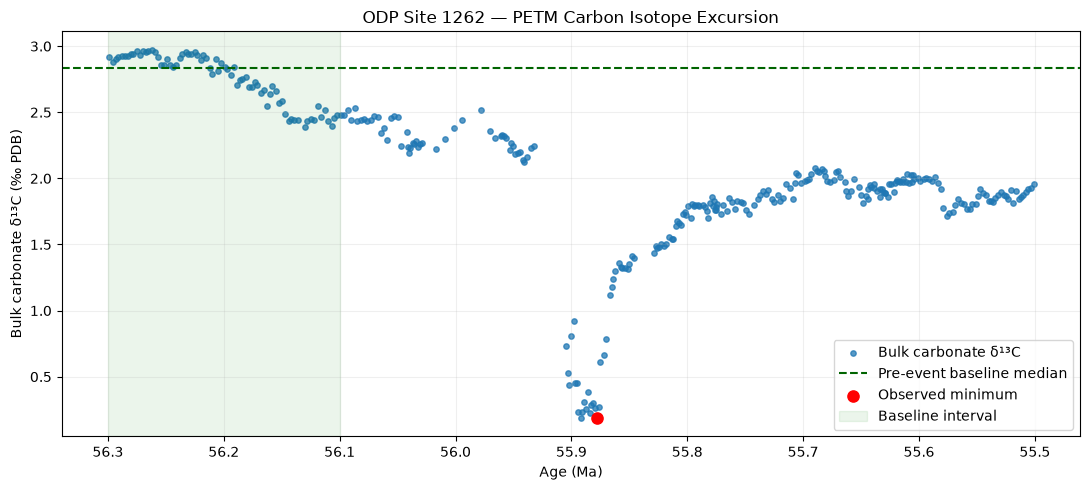

In [5]:
fig, ax = plt.subplots(figsize=(11, 5))

ax.scatter(
    petm["age_ma"],
    petm[carbon_col],
    s=15,
    alpha=0.75,
    label="Bulk carbonate δ¹³C"
)

ax.axhline(
    baseline_median,
    color="darkgreen",
    linestyle="--",
    label="Pre-event baseline median"
)

ax.scatter(
    minimum_row["age_ma"],
    minimum_carbon,
    color="red",
    s=65,
    zorder=5,
    label="Observed minimum"
)

ax.axvspan(
    56.1, 56.3,
    color="green",
    alpha=0.08,
    label="Baseline interval"
)

ax.invert_xaxis()
ax.set_xlabel("Age (Ma)")
ax.set_ylabel("Bulk carbonate δ¹³C (‰ PDB)")
ax.set_title("ODP Site 1262 — PETM Carbon Isotope Excursion")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

Quantify the sampling gap

In [6]:
age_values = np.sort(
    petm["age_ma"].dropna().unique()
)

age_gaps = np.diff(age_values)

gap_table = pd.DataFrame({
    "younger_age_ma": age_values[:-1],
    "older_age_ma": age_values[1:],
    "gap_kyr": age_gaps * 1000
})

display(
    gap_table.sort_values(
        "gap_kyr",
        ascending=False
    ).head(10)
)

,younger_age_ma,older_age_ma,gap_kyr
191,55.905,55.932,27.0
157,55.829,55.846,17.0
209,55.978,55.994,16.0
213,56.017,56.029,12.0
211,56.001,56.009,8.0
208,55.970,55.978,8.0
212,56.009,56.017,8.0
210,55.994,56.001,7.0
253,56.130,56.136,6.0
206,55.961,55.966,5.0


Test whether the CIE amplitude depends on baseline selection

In [7]:
baseline_windows = {
    "56.10–56.30 Ma": (56.10, 56.30),
    "56.15–56.30 Ma": (56.15, 56.30),
    "56.20–56.30 Ma": (56.20, 56.30)
}

results = []

for name, (young, old) in baseline_windows.items():

    values = df.loc[
        df["age_ma"].between(young, old),
        carbon_col
    ].dropna()

    results.append({
        "baseline_window": name,
        "n": len(values),
        "baseline_median": values.median(),
        "cie_amplitude": values.median() - minimum_carbon
    })

sensitivity = pd.DataFrame(results)

display(sensitivity)

,baseline_window,n,baseline_median,cie_amplitude
0,56.10–56.30 Ma,74,2.836,2.649
1,56.15–56.30 Ma,58,2.875,2.688
2,56.20–56.30 Ma,38,2.922,2.735


## Preliminary PETM carbon isotope excursion analysis

The ODP Site 1262 bulk carbonate δ¹³C record was examined over an exploratory interval of 56.3–55.5 Ma. A pre-excursion reference interval of 56.3–56.1 Ma was selected for initial descriptive analysis.

The median δ¹³C value within this interval was used as the preliminary baseline. The minimum observed δ¹³C value was identified within the broader analysis window, and the excursion amplitude was calculated as the difference between the baseline median and the observed minimum.

The analysis was repeated using alternative pre-event reference intervals to evaluate sensitivity to baseline selection.

Sampling resolution was assessed using the differences between successive unique reported ages. These age increments were used to identify intervals in which the timing of isotopic change is poorly constrained.

All calculations were performed using the original published isotope measurements without interpolation, smoothing or manual correction. The resulting excursion amplitude is treated as a preliminary descriptive estimate rather than a definitive reconstruction of the full PETM carbon isotope excursion.

Produce a numerical results summary

In [8]:
summary = pd.DataFrame({
    "Metric": [
        "Total observations",
        "PETM-window observations",
        "Baseline observations",
        "Baseline median δ13C (‰)",
        "Observed minimum δ13C (‰)",
        "Age of minimum (Ma)",
        "Depth of minimum (m)",
        "Baseline-to-minimum amplitude (‰)",
        "Largest age gap (kyr)"
    ],
    "Value": [
        len(df),
        len(petm),
        len(baseline),
        baseline_median,
        minimum_carbon,
        minimum_row["age_ma"],
        minimum_row["Depth sed [m]"],
        cie_amplitude,
        gap_table["gap_kyr"].max()
    ]
})

display(summary)

,Metric,Value
0,Total observations,4364.000
1,PETM-window observations,324.000
2,Baseline observations,74.000
3,Baseline median δ13C (‰),2.836
4,Observed minimum δ13C (‰),0.187
5,Age of minimum (Ma),55.878
6,Depth of minimum (m),139.820
7,Baseline-to-minimum amplitude (‰),2.649
8,Largest age gap (kyr),27.000


Interpret baseline sensitivity

In [9]:
display(
    sensitivity.sort_values("baseline_window")
)

amplitude_range = (
    sensitivity["cie_amplitude"].max()
    - sensitivity["cie_amplitude"].min()
)

print(
    f"Range of estimated CIE amplitudes: "
    f"{amplitude_range:.3f} ‰"
)

,baseline_window,n,baseline_median,cie_amplitude
0,56.10–56.30 Ma,74,2.836,2.649
1,56.15–56.30 Ma,58,2.875,2.688
2,56.20–56.30 Ma,38,2.922,2.735


Range of estimated CIE amplitudes: 0.086 ‰


Identify the largest sampling gaps

In [10]:
largest_gaps = (
    gap_table
    .sort_values("gap_kyr", ascending=False)
    .head(10)
    .copy()
)

display(largest_gaps)

,younger_age_ma,older_age_ma,gap_kyr
191,55.905,55.932,27.0
157,55.829,55.846,17.0
209,55.978,55.994,16.0
213,56.017,56.029,12.0
211,56.001,56.009,8.0
208,55.970,55.978,8.0
212,56.009,56.017,8.0
210,55.994,56.001,7.0
253,56.130,56.136,6.0
206,55.961,55.966,5.0


PETM isotope figure

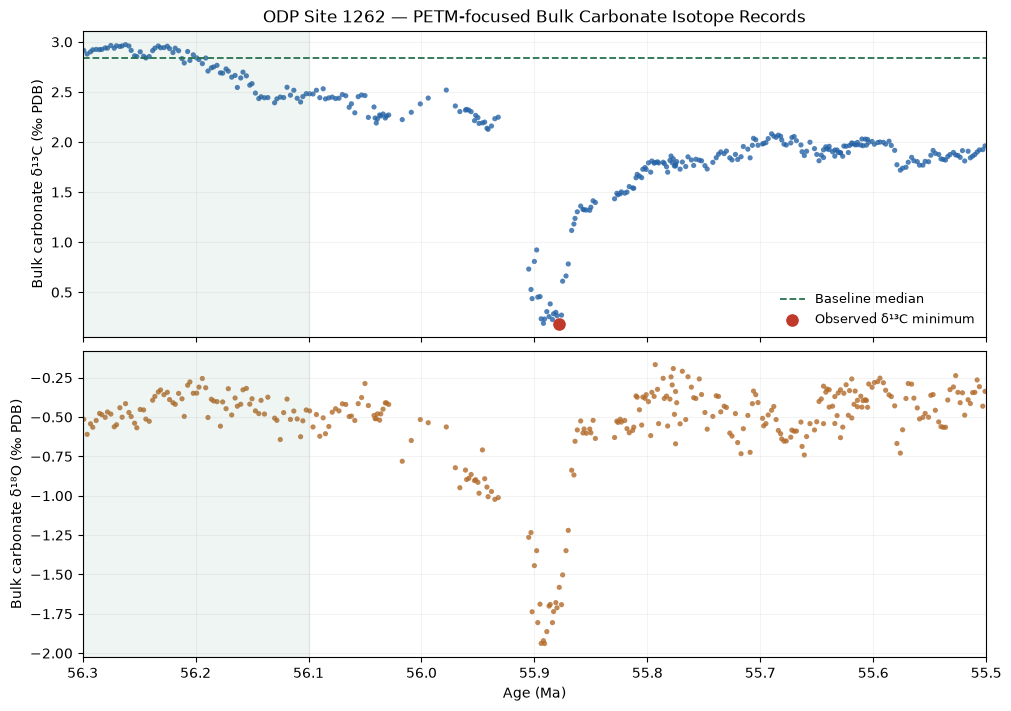

In [11]:
from pathlib import Path
import matplotlib.pyplot as plt

# Create a folder for generated figures
figure_dir = root / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(
    2, 1,
    figsize=(10, 7),
    sharex=True,
    constrained_layout=True
)

# Panel A: Carbon isotopes
axes[0].scatter(
    petm["age_ma"],
    petm[carbon_col],
    s=14,
    color="#2563A6",
    alpha=0.8,
    edgecolors="none"
)

axes[0].axhline(
    baseline_median,
    color="#26734D",
    linestyle="--",
    linewidth=1.3,
    label="Baseline median"
)

axes[0].scatter(
    minimum_row["age_ma"],
    minimum_carbon,
    s=65,
    color="#C0392B",
    zorder=5,
    label="Observed δ¹³C minimum"
)

axes[0].set_ylabel("Bulk carbonate δ¹³C (‰ PDB)")
axes[0].legend(frameon=False, fontsize=9)
axes[0].grid(alpha=0.15)

# Panel B: Oxygen isotopes
axes[1].scatter(
    petm["age_ma"],
    petm[oxygen_col],
    s=14,
    color="#B26A29",
    alpha=0.8,
    edgecolors="none"
)

axes[1].set_ylabel("Bulk carbonate δ¹⁸O (‰ PDB)")
axes[1].set_xlabel("Age (Ma)")
axes[1].grid(alpha=0.15)

# Highlight the baseline interval in both panels
for ax in axes:
    ax.axvspan(
        56.1, 56.3,
        color="#26734D",
        alpha=0.07
    )
    ax.set_xlim(56.3, 55.5)

axes[0].set_title(
    "ODP Site 1262 — PETM-focused Bulk Carbonate Isotope Records"
)

# Save both raster and vector versions
fig.savefig(
    figure_dir / "site1262_petm_isotopes.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    figure_dir / "site1262_petm_isotopes.pdf",
    bbox_inches="tight"
)

plt.show()

baseline-sensitivity figure

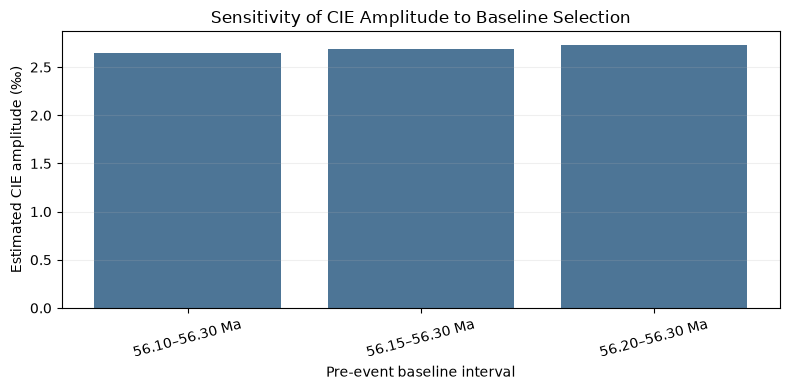

In [12]:
fig, ax = plt.subplots(figsize=(8, 4))

ax.bar(
    sensitivity["baseline_window"],
    sensitivity["cie_amplitude"],
    color="#4D7596"
)

ax.set_xlabel("Pre-event baseline interval")
ax.set_ylabel("Estimated CIE amplitude (‰)")
ax.set_title("Sensitivity of CIE Amplitude to Baseline Selection")

ax.tick_params(axis="x", rotation=15)
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()

fig.savefig(
    figure_dir / "site1262_baseline_sensitivity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Export results as CSV files

In [13]:
results_dir = root / "results"
results_dir.mkdir(parents=True, exist_ok=True)

summary.to_csv(
    results_dir / "petm_excursion_summary.csv",
    index=False
)

sensitivity.to_csv(
    results_dir / "petm_baseline_sensitivity.csv",
    index=False
)

largest_gaps.to_csv(
    results_dir / "petm_largest_age_gaps.csv",
    index=False
)

print("Results exported successfully.")

Results exported successfully.


methods and limitations
## Preliminary Results and Interpretation

The bulk carbonate δ¹³C and δ¹⁸O records from ODP Site 1262 were examined across the 56.3–55.5 Ma interval to characterize isotopic variability associated with the Paleocene–Eocene Thermal Maximum.

A pre-event reference interval of 56.3–56.1 Ma was used to calculate the median δ¹³C baseline. The observed minimum δ¹³C value was identified within the broader analysis interval, and the baseline-to-minimum difference was used as a preliminary estimate of carbon isotope excursion amplitude.

The sensitivity of this estimate was evaluated using three alternative pre-event baseline windows. Sampling resolution was assessed through the differences between successive unique reported ages.

The isotope records display a pronounced negative carbon isotope excursion and a broadly associated negative oxygen isotope shift near 55.9 Ma. However, the timing and rate of the initial isotopic transition remain limited by the sampling distribution and the published age model.

The observed δ¹³C minimum is not interpreted as the geological onset of the PETM. Similarly, the preliminary excursion amplitude is not assumed to represent the full global carbon isotope excursion.

All raw observations and reported age assignments were preserved. No interpolation, smoothing, or automatic outlier removal was applied.

### Numerical results to insert after verification

- Pre-event baseline median: [2.8360000000000003] ‰
- Observed δ¹³C minimum: [0.187] ‰
- Age of minimum: [55.878] Ma
- Preliminary CIE amplitude: [2.649] ‰
- Largest age gap in the analysis window: [27] kyr
- Amplitude sensitivity across tested baselines: [2.5] ‰

### Carbon and oxygen isotope variability across the PETM

The ODP Site 1262 bulk carbonate isotope record comprises 4,364 observations, of which 324 fall within the selected 56.3–55.5 Ma interval. The δ¹³C record exhibits a pronounced negative excursion near 55.9 Ma, reaching a minimum observed value of 0.187‰ at 55.878 Ma and a sediment depth of 139.820 m.

The median pre-excursion δ¹³C value calculated over 56.3–56.1 Ma is 2.836‰, yielding a preliminary baseline-to-minimum excursion amplitude of 2.649‰. Alternative baseline intervals produce amplitude estimates between 2.649‰ and 2.735‰, corresponding to a sensitivity range of 0.086‰.

A 27 kyr interval without reported observations occurs between 55.932 and 55.905 Ma, adjacent to the rapid negative shift. Consequently, the precise timing and rate of the excursion onset remain insufficiently constrained by the sampled record.

A broadly associated negative δ¹⁸O shift is also observed, although its environmental significance requires consideration of the bulk carbonate proxy characteristics and preservation.

These results provide a quantitative description of the isotope excursion but do not independently establish its geological onset, duration, or recovery boundary.